<style>
body {
    font-family: 'Times New Roman', Times, serif;
}

.custom-spacing {
    line-height: 0.5;
}
</style>

<h2 style="text-align:center;font-family: 'Times New Roman'; font-weight:bold; font-size:24px;">
KECERDASAN ARTIFICIAL INTELLIGENCE GEOFISIKA
</h2>

<h3 style="text-align:center; font-family: 'Times New Roman'; font-weight:bold; font-size:20px;">
IMPLEMENTASI RECIPE SEMUA PELAJARAN DI KELAS
</h3>


<div style="text-align:center;">
  <img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
       alt="Logo Unhas" 
       style="width:260px;">
</div>

<br>

<h4 style="text-align:center; font-weight:bold;font-family: 'Times New Roman'; font-size:15px;">
DISUSUN OLEH:
</h4>

<p style="text-align:center; font-weight:bold;font-family: 'Times New Roman'; font-size:17px;">
MARDARIFAL HAUTEAS (H061241012)
</p>

<br>

<p style="text-align:center; font-weight:bold; font-family: 'Times New Roman'; font-size:17px;">
PROGRAM STUDI GEOFISIKA
</p>

<p style="text-align:center; font-family: 'Times New Roman'; font-weight:bold; font-size:17px;">
FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM
</p>

<p style="text-align:center; font-family: 'Times New Roman';  font-weight:bold; font-size:17px;">
UNIVERSITAS HASANUDDIN
</p>

<p style="text-align:center; font-family: 'Times New Roman';  font-weight:bold; font-size:17px;">
MAKASSAR
</p>

<p style="text-align:center; font-family: 'Times New Roman'; font-weight:bold; font-size:17px;">
2026
</p>

<div style="font-family:'Times New Roman'; font-size:12pt; text-align:justify; line-height:1.5;">

### **STUDI KASUS**

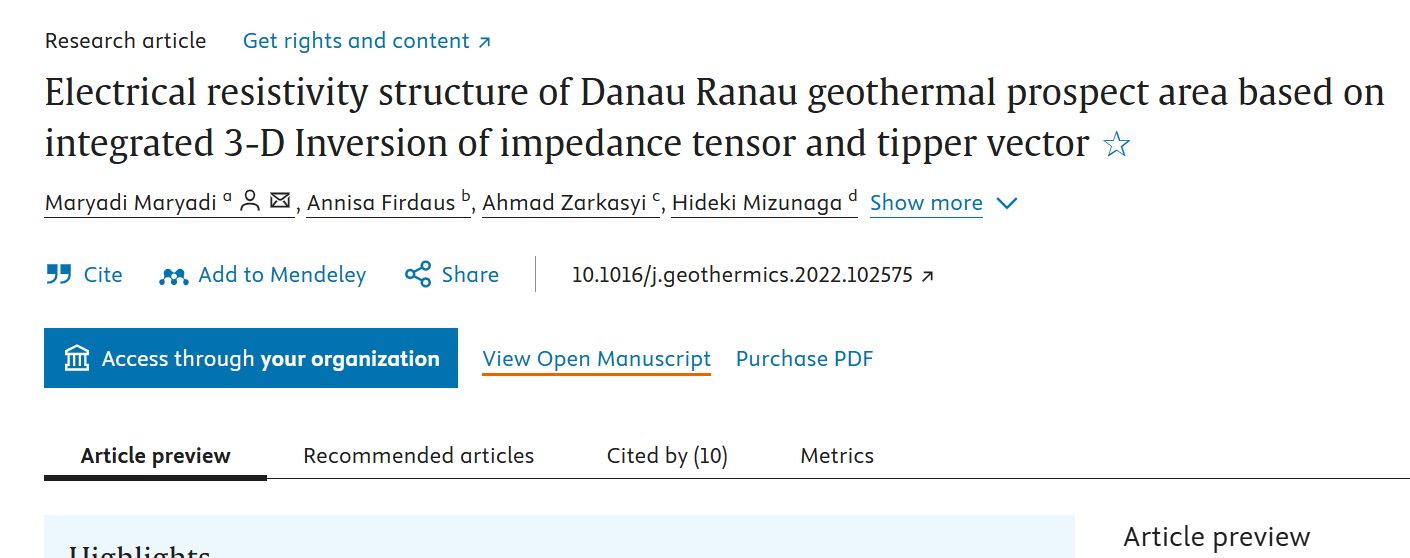

<div style="font-family:'Times New Roman'; font-size:12pt; text-align:justify; line-height:1.5;">

Penelitian di lapangan panas bumi Danau Ranau, Sumatra, dilakukan untuk mengetahui kondisi bawah permukaan dan mengidentifikasi struktur yang berhubungan dengan sistem geotermal. Permasalahan yang dikaji adalah bagaimana distribusi resistivitas batuan dapat digunakan untuk mengenali lapisan penudung (cap rock), zona reservoar, dan struktur sesar. Penelitian ini menggunakan metode Magnetotellurik (MT) yang memanfaatkan variasi medan elektromagnetik alami untuk memperkirakan resistivitas batuan hingga kedalaman tertentu.

Data MT diolah menggunakan inversi tiga dimensi (3D) dengan menggabungkan impedance tensor dan tipper vector. Hasil pemodelan menunjukkan zona resistivitas rendah yang diinterpretasikan sebagai lapisan penudung serta zona yang relatif lebih resistif di bawah Gunung Seminung yang diperkirakan berkaitan dengan reservoar panas bumi. Struktur sesar juga diinterpretasikan berperan dalam mengontrol pergerakan fluida hidrotermal. Hasil penelitian ini memberikan gambaran mengenai struktur sistem panas bumi Danau Ranau dan membantu menentukan zona yang berpotensi untuk eksplorasi lebih lanjut.

R-CS-005 | Danau Ranau 1D MT Forward Modeling
Skin depth @ 1 Hz    ≈ 3557 m
Skin depth @ 0.01 Hz ≈ 35567 m
Jumlah frekuensi     : 50


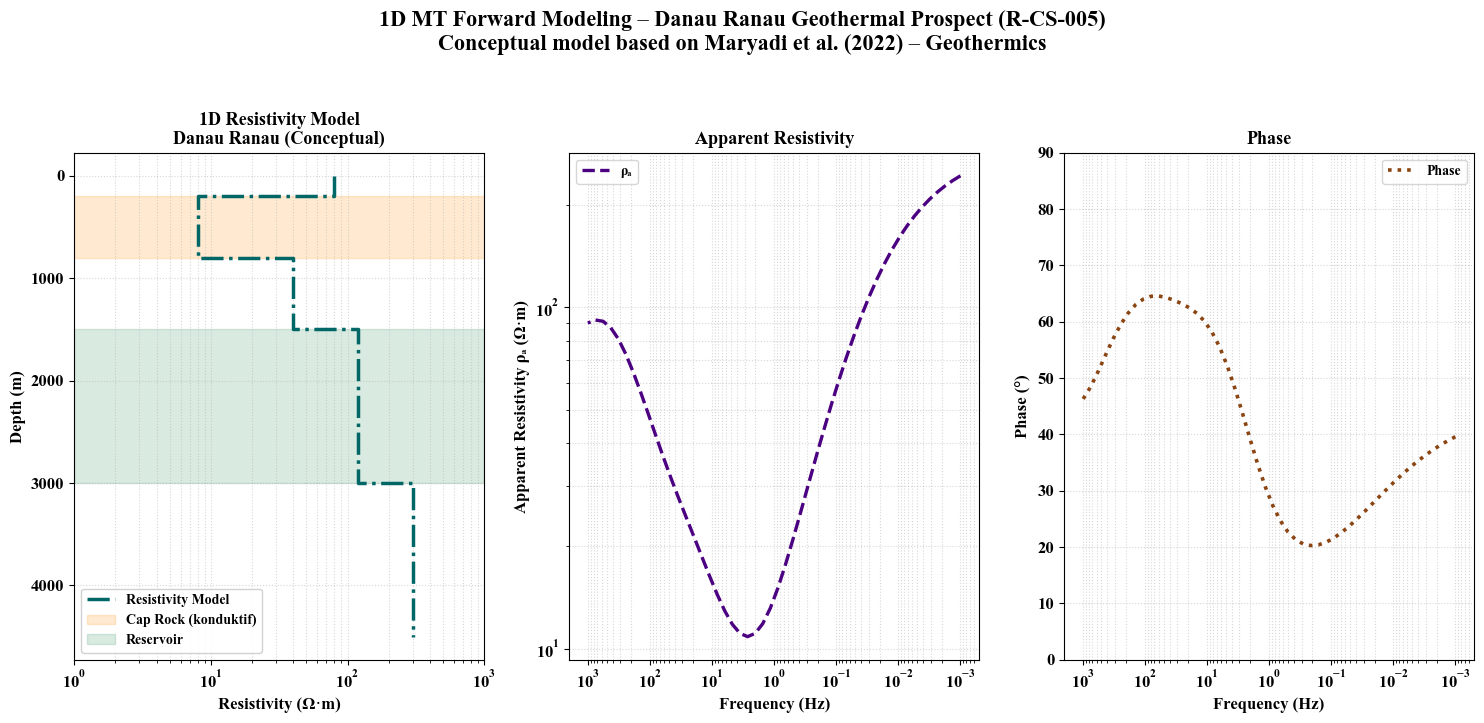


Ringkasan Model:
  Cap rock     : 200–800 m   → 8.0 Ω·m (konduktif)
  Reservoir    : 1500–3000 m → 120.0 Ω·m (lebih resistif)
  ρₐ range     : 10.9 – 243.0 Ω·m
  Phase range  : 20.3 – 64.6 °


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# R-CS-005 | 1D MT Forward Modeling
# Danau Ranau Geothermal Prospect
# Conceptual model based on Maryadi et al. (2022)
# ==========================================

# ------------------------------------------
# Pengaturan Font Global (Times New Roman)
# ------------------------------------------
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'

# ------------------------------------------
# 1. PARAMETER MODEL BERLAPIS (KONSEPTUAL)
# ------------------------------------------
thickness = np.array([200.0, 600.0, 700.0, 1500.0])          # m
resistivity = np.array([80.0, 8.0, 40.0, 120.0, 300.0])       # Ohm.m

# Layer 1: Overburden          (0-200 m)     → 80 Ω·m
# Layer 2: Cap rock (konduktif)(200-800 m)   → 8 Ω·m
# Layer 3: Transisi            (800-1500 m)  → 40 Ω·m
# Layer 4: Reservoir           (1500-3000 m) → 120 Ω·m
# Layer 5: Basement            (>3000 m)     → 300 Ω·m

# ------------------------------------------
# 2. FREKUENSI & KONSTANTA FISIKA
# ------------------------------------------
freqs = np.logspace(-3, 3, 50)
mu0 = 4 * np.pi * 1e-7

# ------------------------------------------
# 3. FUNGSI FORWARD MODELING 1D MT
# ------------------------------------------
def mt_1d_forward(thickness, resistivity, freqs):
    n_layers = len(resistivity)
    n_freq = len(freqs)
    
    rho_a = np.zeros(n_freq)
    phase = np.zeros(n_freq)
    
    for i, f in enumerate(freqs):
        w = 2 * np.pi * f
        
        # Half-space
        k = np.sqrt(1j * w * mu0 / resistivity[-1])
        Z = 1j * w * mu0 / k
        
        # Rekursi dari bawah ke atas
        for j in range(n_layers - 2, -1, -1):
            k = np.sqrt(1j * w * mu0 / resistivity[j])
            Z_layer = 1j * w * mu0 / k
            tanh_term = np.tanh(k * thickness[j])
            Z = Z_layer * (Z + Z_layer * tanh_term) / (Z_layer + Z * tanh_term)
        
        rho_a[i] = (1 / (w * mu0)) * np.abs(Z)**2
        phase[i] = np.angle(Z, deg=True)
    
    return rho_a, phase

rho_a, phase = mt_1d_forward(thickness, resistivity, freqs)

# ------------------------------------------
# 4. SKIN DEPTH (CHECK)
# ------------------------------------------
rho_avg = 50.0
skin_1hz = 503 * np.sqrt(rho_avg / 1.0)
skin_001hz = 503 * np.sqrt(rho_avg / 0.01)

print("=" * 55)
print("R-CS-005 | Danau Ranau 1D MT Forward Modeling")
print("=" * 55)
print(f"Skin depth @ 1 Hz    ≈ {skin_1hz:.0f} m")
print(f"Skin depth @ 0.01 Hz ≈ {skin_001hz:.0f} m")
print(f"Jumlah frekuensi     : {len(freqs)}")
print("=" * 55)

# ------------------------------------------
# 5. VISUALISASI (PAPER-READY)
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 7))

# ---- Panel 1: Model Resistivitas ----
ax1 = axes[0]
depth_top = np.cumsum(np.concatenate(([0], thickness)))
depth_plot = []
rho_plot = []

for i in range(len(thickness)):
    depth_plot.extend([depth_top[i], depth_top[i+1]])
    rho_plot.extend([resistivity[i], resistivity[i]])

depth_plot.extend([depth_top[-1], depth_top[-1] + 1500])
rho_plot.extend([resistivity[-1], resistivity[-1]])

# Garis model: dark teal + dash-dot
ax1.plot(rho_plot, depth_plot, color='#006666', linestyle='-.', linewidth=2.5, label='Resistivity Model')

ax1.set_xscale('log')
ax1.set_xlabel("Resistivity (Ω·m)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Depth (m)", fontsize=12, fontweight='bold')
ax1.set_title("1D Resistivity Model\nDanau Ranau (Conceptual)", fontsize=13, fontweight='bold')
ax1.invert_yaxis()
ax1.grid(True, which='both', linestyle=':', alpha=0.5)
ax1.set_xlim(1, 1000)

# Highlight zona dengan warna berbeda
ax1.axhspan(200, 800, color='#FF8C00', alpha=0.18, label='Cap Rock (konduktif)')      # Orange
ax1.axhspan(1500, 3000, color='#2E8B57', alpha=0.18, label='Reservoir')               # Sea Green
ax1.legend(loc='lower left', fontsize=10, framealpha=0.9)

# ---- Panel 2: Apparent Resistivity ----
ax2 = axes[1]
# Garis ρₐ: ungu tua + dashed
ax2.loglog(freqs, rho_a, color='#4B0082', linestyle='--', linewidth=2.4, label='ρₐ')

ax2.set_xlabel("Frequency (Hz)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Apparent Resistivity ρₐ (Ω·m)", fontsize=12, fontweight='bold')
ax2.set_title("Apparent Resistivity", fontsize=13, fontweight='bold')
ax2.grid(True, which='both', linestyle=':', alpha=0.5)
ax2.invert_xaxis()
ax2.legend(loc='best', fontsize=10)

# ---- Panel 3: Phase ----
ax3 = axes[2]
# Garis phase: coklat kemerahan + dotted
ax3.semilogx(freqs, phase, color='#8B4513', linestyle=':', linewidth=2.6, label='Phase')

ax3.set_xlabel("Frequency (Hz)", fontsize=12, fontweight='bold')
ax3.set_ylabel("Phase (°)", fontsize=12, fontweight='bold')
ax3.set_title("Phase", fontsize=13, fontweight='bold')
ax3.grid(True, which='both', linestyle=':', alpha=0.5)
ax3.invert_xaxis()
ax3.set_ylim(0, 90)
ax3.legend(loc='best', fontsize=10)

# Judul utama (16 pt Bold)
plt.suptitle("1D MT Forward Modeling – Danau Ranau Geothermal Prospect (R-CS-005)\n"
             "Conceptual model based on Maryadi et al. (2022) – Geothermics",
             fontsize=16, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. RINGKASAN HASIL
# ------------------------------------------
print("\nRingkasan Model:")
print(f"  Cap rock     : 200–800 m   → {resistivity[1]} Ω·m (konduktif)")
print(f"  Reservoir    : 1500–3000 m → {resistivity[3]} Ω·m (lebih resistif)")
print(f"  ρₐ range     : {rho_a.min():.1f} – {rho_a.max():.1f} Ω·m")
print(f"  Phase range  : {phase.min():.1f} – {phase.max():.1f} °")

<div style="font-family:'Times New Roman'; font-size:12pt; text-align:justify; line-height:1.5;">

### **ANALISA GAMBAR**

<div style="font-family:'Times New Roman'; font-size:12pt; text-align:justify; line-height:1.5;">

Gambar di atas menunjukkan hasil pemodelan 1D Magnetotellurik untuk prospek panas bumi Danau Ranau. Pada panel kiri terlihat struktur resistivitas bawah permukaan, yaitu lapisan penudung (*cap rock*) yang bersifat konduktif dengan resistivitas rendah sekitar $8\ \Omega \cdot \text{m}$ pada kedalaman 200–800 meter. Sementara itu, zona reservoar yang lebih resistif dengan nilai sekitar $120\ \Omega \cdot \text{m}$ diperkirakan berada pada kedalaman 1.500–3.000 meter. Pola ini sesuai dengan gambaran umum struktur resistivitas pada sistem panas bumi.

Panel tengah dan kanan memperlihatkan respons data MT yang dihasilkan dari model tersebut. Nilai resistivitas semu (*apparent resistivity*) mengalami penurunan tajam pada frekuensi menengah akibat pengaruh lapisan konduktif di atasnya, kemudian meningkat kembali pada frekuensi rendah yang berkaitan dengan zona lebih resistif di kedalaman. Kurva fase (*phase*) juga menunjukkan perubahan respons yang konsisten dengan variasi resistivitas bawah permukaan. Secara keseluruhan, hasil pemodelan ini menggambarkan bagaimana struktur resistivitas di daerah panas bumi Danau Ranau dapat diidentifikasi melalui metode Magnetotellurik.